# Model training, comparison and selection
Chronological validation only. Nothing here is tuned on a random split, and the hidden test set is never touched.

In [1]:
import time, json, warnings, pickle
import numpy as np, pandas as pd, matplotlib; matplotlib.use('Agg'); import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import TimeSeriesSplit
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error, mean_absolute_error
import lightgbm as lgb, xgboost as xgb
from features import *
warnings.filterwarnings('ignore'); pd.set_option('display.width',220)
rmse = lambda y,p: float(np.sqrt(mean_squared_error(y,p))); mae = lambda y,p: float(mean_absolute_error(y,p))

## 1. Chronological split
Latest 20 % of rows = validation. One row between them is dropped (the last training label equals the first validation row's `Usage_kWh`). Features are built from past timestamps only, so validation rows may look back into the training period — exactly what happens in deployment.

In [2]:
df = pd.read_csv('train.csv'); y = df[TARGET].values; n = len(df); split = int(n*0.8)
tr = np.arange(0, split-1); va = np.arange(split, n)
Xraw,_ = build_features(df, engineered=False); Xfe, ts = build_features(df)
print('train', ts[tr[0]], '->', ts[tr[-1]], len(tr), 'rows'); print('valid', ts[va[0]], '->', ts[va[-1]], len(va), 'rows')
print('NaNs in validation features (all engineered):', int(Xfe.iloc[va].isna().sum().sum()), '-> no validation row was dropped')

train 2018-01-01 00:15:00 -> 2018-08-22 13:45:00 22423 rows
valid 2018-08-22 14:15:00 -> 2018-10-19 23:45:00 5607 rows
NaNs in validation features (all engineered): 0 -> no validation row was dropped


## 2. Baselines and model comparison
The same validation rows are used for every row of the table. "raw" = the given columns + time-of-day/weekday encodings; "engineered" = raw + lags/rolling statistics (all 32 features).

In [3]:
rows=[]; cur = Xraw.Usage_kWh.values
yd, yw = Xfe.lag_95.values, Xfe.lag_671.values
for nm,p in [('Persistence (Usage_t)',cur),('Seasonal naive: same slot yesterday',np.where(np.isnan(yd),cur,yd)),('Seasonal naive: same slot last week',np.where(np.isnan(yw),cur,yw))]:
    rows.append(dict(model=nm,features='-',val_RMSE=rmse(y[va],p[va]),val_MAE=mae(y[va],p[va]),train_RMSE=np.nan,train_MAE=np.nan,seconds=0.0))
def candidates():
    imp = lambda m: make_pipeline(SimpleImputer(strategy='median'), m)
    return {'Ridge': make_pipeline(SimpleImputer(strategy='median'),StandardScaler(),Ridge(1.0)),
     'RandomForest': imp(RandomForestRegressor(300,min_samples_leaf=3,n_jobs=-1,random_state=42)),
     'ExtraTrees': imp(ExtraTreesRegressor(300,min_samples_leaf=3,n_jobs=-1,random_state=42)),
     'HistGradientBoosting': imp(HistGradientBoostingRegressor(random_state=42)),
     'LightGBM': imp(lgb.LGBMRegressor(n_estimators=500,learning_rate=0.03,num_leaves=31,subsample=0.8,subsample_freq=1,colsample_bytree=0.8,random_state=42,verbose=-1)),
     'XGBoost': imp(xgb.XGBRegressor(n_estimators=500,learning_rate=0.03,max_depth=5,subsample=0.8,colsample_bytree=0.8,random_state=42,n_jobs=-1))}
for fn,X in [('raw',Xraw),('engineered (32)',Xfe)]:
    for nm,m in candidates().items():
        t=time.time(); m.fit(X.iloc[tr],y[tr]); rows.append(dict(model=nm,features=fn,val_RMSE=rmse(y[va],m.predict(X.iloc[va])),val_MAE=mae(y[va],m.predict(X.iloc[va])),
            train_RMSE=rmse(y[tr],m.predict(X.iloc[tr])),train_MAE=mae(y[tr],m.predict(X.iloc[tr])),seconds=round(time.time()-t,1)))
res = pd.DataFrame(rows).round(3); res.to_csv('results_model_comparison.csv',index=False); res

,model,features,val_RMSE,val_MAE,train_RMSE,train_MAE,seconds
0,Persistence (Usage_t),-,11.945,5.277,NaN,NaN,0.0
1,Seasonal naive: same slot yesterday,-,26.689,13.813,NaN,NaN,0.0
2,Seasonal naive: same slot last week,-,23.578,12.193,NaN,NaN,0.0
3,Ridge,raw,11.455,6.361,14.088,7.849,0.1
4,RandomForest,raw,8.876,4.050,6.322,2.969,13.5
5,ExtraTrees,raw,8.961,4.125,6.314,3.021,7.1
6,HistGradientBoosting,raw,8.634,3.989,9.299,4.619,0.4
7,LightGBM,raw,8.652,3.969,8.609,4.297,0.9
8,XGBoost,raw,8.753,4.108,9.030,4.529,0.6
9,Ridge,engineered (32),10.347,5.804,12.635,7.356,0.1


**Reading the table:** every tree/boosting model beats persistence clearly; Ridge barely does (the relationship is non-linear: the plant switches between idle and production). Seasonal-naive is much *worse* than persistence, so this plant does not repeat yesterday/last week closely. Random Forest / Extra Trees fit the training set much more tightly than they generalise (train RMSE ≈ 4-5 vs validation ≈ 8.4), i.e. they overfit more than boosting.

## 3. Which engineered features help? (ablation, LightGBM)
Feature sets are compared by **time-series CV on the training period only** (5 expanding folds) and then, once, on the validation period.

In [4]:
B = BASIC_COLUMNS; short=['lag_1','lag_2','lag_3','lag_4','lag_8','diff_1','diff_4']
r4 = ['roll_mean_4','roll_std_4','roll_mean_16','roll_std_16']; r96=['roll_mean_96','roll_std_96']
sets = {'A basic (given cols + time encodings)':B, 'B + short lags (1-4, 8) + diffs':B+short, 'C = B + rolling 1h/4h':B+short+r4,
        'D = C + rolling 24h  (SELECTED)':B+short+r4+r96, 'E = all incl. 1-day/1-week lags':list(Xfe.columns)}
assert sets['D = C + rolling 24h  (SELECTED)']==SELECTED_FEATURES or set(sets['D = C + rolling 24h  (SELECTED)'])==set(SELECTED_FEATURES)
P = dict(n_estimators=500,learning_rate=0.03,num_leaves=31,subsample=0.8,subsample_freq=1,colsample_bytree=0.8,random_state=42,verbose=-1)
tscv = TimeSeriesSplit(n_splits=5); out=[]
for k,cols in sets.items():
    cr,ca=[],[]
    for a,b in tscv.split(tr):
        mm = lgb.LGBMRegressor(**P).fit(Xfe.iloc[tr[a]][cols],y[tr[a]]); p=mm.predict(Xfe.iloc[tr[b]][cols]); cr.append(rmse(y[tr[b]],p)); ca.append(mae(y[tr[b]],p))
    mm = lgb.LGBMRegressor(**P).fit(Xfe.iloc[tr][cols],y[tr]); pv=mm.predict(Xfe.iloc[va][cols])
    out.append(dict(feature_set=k,n_features=len(cols),CV_RMSE=np.mean(cr),CV_MAE=np.mean(ca),val_RMSE=rmse(y[va],pv),val_MAE=mae(y[va],pv)))
abl = pd.DataFrame(out).round(3); abl.to_csv('results_feature_sets.csv',index=False); abl

,feature_set,n_features,CV_RMSE,CV_MAE,val_RMSE,val_MAE
0,A basic (given cols + time encodings),14,10.664,5.244,8.652,3.969
1,"B + short lags (1-4, 8) + diffs",21,10.283,5.088,8.208,3.807
2,C = B + rolling 1h/4h,25,10.247,5.078,8.244,3.839
3,D = C + rolling 24h (SELECTED),27,10.245,5.081,8.217,3.812
4,E = all incl. 1-day/1-week lags,32,10.178,5.149,8.291,3.890


**Interpretation (honest):** short lags give the one clear gain (A → B: CV RMSE 10.66 → 10.28, validation RMSE 8.65 → 8.21). Sets B, C, D and E are then essentially tied: validation RMSE spans 8.21–8.29 and CV RMSE 10.18–10.28, against a fold-to-fold spread of ~1.2 — differences this small are within noise (reordering the same columns alone moves scores by ~0.02). The 1-day/1-week lags (set E) give the best CV RMSE but the worst validation MAE of the four, and would require 7 days of history at inference.
I selected **D** as a tie-break, not because it is measurably best: it adds multi-scale recent-load context (1 h / 4 h / 24 h) and needs only 24 h of history, which makes inference more robust. B would have been a defensible choice too.

## 4. Tuning (time-series CV on the training period only)

In [5]:
rng = np.random.RandomState(0); space = dict(num_leaves=[7,15,31,63],learning_rate=[0.02,0.03,0.05],n_estimators=[200,400,700],min_child_samples=[10,20,40,80],subsample=[0.7,0.85,1.0],colsample_bytree=[0.5,0.7,0.9],reg_lambda=[0,1,5,20])
Xs = Xfe[SELECTED_FEATURES]
def cv_score(prm):
    s=[]
    for a,b in tscv.split(tr):
        mm = lgb.LGBMRegressor(**{**P,**prm}).fit(Xs.iloc[tr[a]],y[tr[a]]); s.append(rmse(y[tr[b]],mm.predict(Xs.iloc[tr[b]])))
    return np.mean(s), np.std(s)
trials=[]
for i in range(25):
    prm={k:v[rng.randint(len(v))] for k,v in space.items()}; trials.append((*cv_score(prm),prm))
trials.sort(key=lambda t:t[0]); dflt = cv_score({})
print('default config CV RMSE %.3f +- %.3f'%dflt)
for t in trials[:3]: print('CV RMSE %.3f +- %.3f'%t[:2], t[2])
mm = lgb.LGBMRegressor(**{**P,**trials[0][2]}).fit(Xs.iloc[tr],y[tr]); pv=mm.predict(Xs.iloc[va])
print('best-tuned config on validation: RMSE %.3f MAE %.3f'%(rmse(y[va],pv),mae(y[va],pv)))

default config CV RMSE 10.245 +- 1.254
CV RMSE 10.182 +- 1.146 {'num_leaves': 31, 'learning_rate': 0.02, 'n_estimators': 400, 'min_child_samples': 20, 'subsample': 0.85, 'colsample_bytree': 0.7, 'reg_lambda': 20}
CV RMSE 10.221 +- 1.212 {'num_leaves': 63, 'learning_rate': 0.02, 'n_estimators': 200, 'min_child_samples': 10, 'subsample': 0.85, 'colsample_bytree': 0.9, 'reg_lambda': 0}
CV RMSE 10.231 +- 1.242 {'num_leaves': 31, 'learning_rate': 0.05, 'n_estimators': 200, 'min_child_samples': 20, 'subsample': 0.85, 'colsample_bytree': 0.7, 'reg_lambda': 1}


best-tuned config on validation: RMSE 8.186 MAE 3.861


The best random-search configuration improves CV RMSE only from 10.245 to 10.182 (fold-to-fold std ≈ 1.2) and validation RMSE from 8.217 to 8.186 — a ~0.4 % change, inside noise. The final model therefore keeps the simple default configuration, which avoids over-fitting the search to this particular period.

## 5. Does ensembling help?

In [6]:
Xt,Xv = Xs.iloc[tr],Xs.iloc[va]
mods = {'LightGBM':lgb.LGBMRegressor(**P),'XGBoost':xgb.XGBRegressor(n_estimators=500,learning_rate=0.03,max_depth=5,subsample=0.8,colsample_bytree=0.8,random_state=42,n_jobs=-1),
        'HistGB':make_pipeline(SimpleImputer(strategy='median'),HistGradientBoostingRegressor(random_state=42)),
        'ExtraTrees':make_pipeline(SimpleImputer(strategy='median'),ExtraTreesRegressor(300,min_samples_leaf=3,n_jobs=-1,random_state=42))}
pv={k:m.fit(Xt,y[tr]).predict(Xv) for k,m in mods.items()}
tab=[(k,rmse(y[va],p),mae(y[va],p)) for k,p in pv.items()]
for combo in [('LightGBM','XGBoost'),('LightGBM','XGBoost','HistGB'),('LightGBM','XGBoost','HistGB','ExtraTrees')]:
    p=np.mean([pv[c] for c in combo],axis=0); tab.append(('avg: '+'+'.join(combo),rmse(y[va],p),mae(y[va],p)))
pd.DataFrame(tab,columns=['model','val_RMSE','val_MAE']).round(3)

,model,val_RMSE,val_MAE
0,LightGBM,8.217,3.812
1,XGBoost,8.230,3.871
2,HistGB,8.286,3.898
3,ExtraTrees,8.571,3.916
4,avg: LightGBM+XGBoost,8.190,3.818
5,avg: LightGBM+XGBoost+HistGB,8.190,3.822
6,avg: LightGBM+XGBoost+HistGB+ExtraTrees,8.201,3.808


Averaging LightGBM + XGBoost (+ others) changes validation RMSE by about 0.03 kWh (8.217 → 8.190) — not worth the added complexity and inference cost. **Final choice: a single LightGBM on feature set D** (the best-performing simple model among those tested; no claim that it is the best possible).

## 6. Final model: scores, overfitting check, error analysis

In [7]:
final = make_pipeline(SimpleImputer(strategy='median'), lgb.LGBMRegressor(**P)).fit(Xs.iloc[tr],y[tr]); pv = final.predict(Xs.iloc[va]); pt = final.predict(Xs.iloc[tr])
print('TRAIN  RMSE %.3f  MAE %.3f'%(rmse(y[tr],pt),mae(y[tr],pt))); print('VALID  RMSE %.3f  MAE %.3f'%(rmse(y[va],pv),mae(y[va],pv)))
print('Persistence baseline  RMSE %.3f  MAE %.3f'%(rmse(y[va],cur[va]),mae(y[va],cur[va])))
print('improvement vs persistence: RMSE %.1f%%, MAE %.1f%%'%((1-rmse(y[va],pv)/rmse(y[va],cur[va]))*100,(1-mae(y[va],pv)/mae(y[va],cur[va]))*100))
print('R^2 on validation: %.3f'%(1-np.sum((y[va]-pv)**2)/np.sum((y[va]-y[va].mean())**2)))
print('mean validation target: %.2f kWh -> MAE is %.1f%% of the mean level'%(y[va].mean(),mae(y[va],pv)/y[va].mean()*100))

TRAIN  RMSE 7.120  MAE 3.654
VALID  RMSE 8.189  MAE 3.811
Persistence baseline  RMSE 11.945  MAE 5.277
improvement vs persistence: RMSE 31.4%, MAE 27.8%
R^2 on validation: 0.924
mean validation target: 23.23 kWh -> MAE is 16.4% of the mean level


--- by Load_Type (MAE: model vs persistence) ---
                ae  ae_persist
load                          
Light_Load    1.28        1.62
Maximum_Load  8.51       11.98
Medium_Load   4.99        7.04
--- by WeekStatus ---
           ae  ae_persist
wk                       
Weekday  4.54        6.56
Weekend  1.89        1.87
--- top 10% of intervals (target >= 62.5 kWh): MAE model 15.20, persistence 20.08; mean signed error (y-pred) 10.27 ---
--- intervals where load changes by >20 kWh: 9.0% of rows, MAE model 17.88 vs persistence 33.77; steady rows MAE 2.42 ---


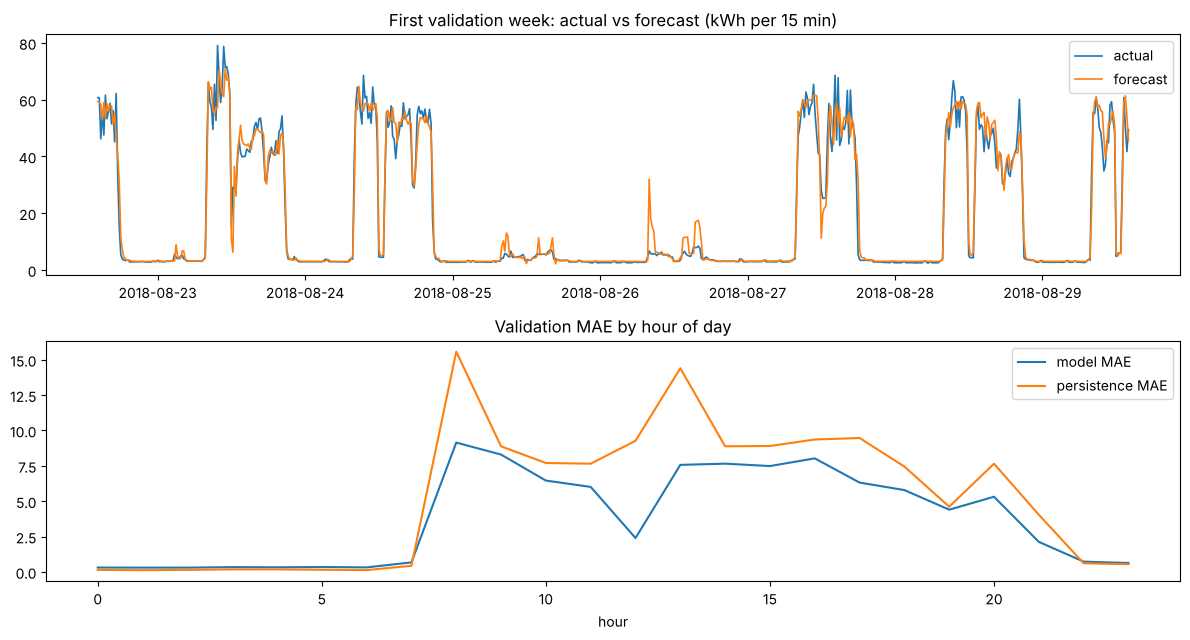

In [8]:
v = pd.DataFrame({'y':y[va],'p':pv,'cur':cur[va],'load':df.Load_Type.values[va],'hour':(df.NSM.values[va]//3600),'wk':df.WeekStatus.values[va]})
v['ae']=(v.y-v.p).abs(); v['ae_persist']=(v.y-v.cur).abs()
print('--- by Load_Type (MAE: model vs persistence) ---'); print(v.groupby('load')[['ae','ae_persist']].mean().round(2))
print('--- by WeekStatus ---'); print(v.groupby('wk')[['ae','ae_persist']].mean().round(2))
hi = v.y>=v.y.quantile(0.9); print('--- top 10%% of intervals (target >= %.1f kWh): MAE model %.2f, persistence %.2f; mean signed error (y-pred) %.2f ---'%(v.y.quantile(.9),v[hi].ae.mean(),v[hi].ae_persist.mean(),(v[hi].y-v[hi].p).mean()))
# big-jump moments: where the load switches state, forecasting is hardest
v['jump']=(v.y-v.cur).abs()>20; print('--- intervals where load changes by >20 kWh: %.1f%% of rows, MAE model %.2f vs persistence %.2f; steady rows MAE %.2f ---'%(v.jump.mean()*100,v[v.jump].ae.mean(),v[v.jump].ae_persist.mean(),v[~v.jump].ae.mean()))
fig,ax=plt.subplots(2,1,figsize=(12,6.5)); sl=slice(0,96*7)
ax[0].plot(ts.values[va][sl],v.y.values[sl],label='actual',lw=1.2); ax[0].plot(ts.values[va][sl],v.p.values[sl],label='forecast',lw=1.2); ax[0].legend(); ax[0].set_title('First validation week: actual vs forecast (kWh per 15 min)')
h=v.groupby('hour')[['ae','ae_persist']].mean(); ax[1].plot(h.index,h.ae,label='model MAE'); ax[1].plot(h.index,h.ae_persist,label='persistence MAE'); ax[1].set_title('Validation MAE by hour of day'); ax[1].set_xlabel('hour'); ax[1].legend()
plt.tight_layout(); plt.savefig('figures/validation_forecast.png',dpi=120); plt.show()

## 7. What drives the predictions? (permutation importance on validation)
Permutation importance = how much RMSE worsens when one column is shuffled. It describes **what this model relies on, not what causes consumption**; correlated columns (usage, CO2, reactive power) share credit.

Usage_kWh                               19.817
tod_cos                                  2.834
CO2(tCO2)                                1.123
Lagging_Current_Reactive.Power_kVarh     0.816
diff_1                                   0.653
lag_1                                    0.583
Leading_Current_Reactive_Power_kVarh     0.442
tod_sin                                  0.428
NSM                                      0.397
lag_4                                    0.336
diff_4                                   0.283
roll_std_16                              0.224


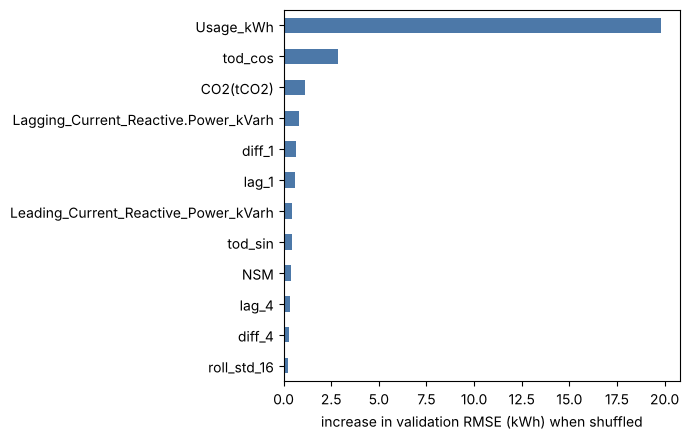

In [9]:
pi = permutation_importance(final, Xs.iloc[va], y[va], scoring='neg_root_mean_squared_error', n_repeats=5, random_state=0, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=SELECTED_FEATURES).sort_values(ascending=False)
print(imp.head(12).round(3).to_string()); imp.to_csv('results_permutation_importance.csv')
imp.head(12)[::-1].plot.barh(figsize=(7,4.5),color='#4C78A8'); plt.xlabel('increase in validation RMSE (kWh) when shuffled'); plt.tight_layout(); plt.savefig('figures/permutation_importance.png',dpi=120); plt.show()

## 8. Final artifact
`train_model.py` repeats the 80/20 evaluation above, then refits the same configuration on **all** labelled rows and saves `model.joblib` (the hidden test period comes after the training data, so the newest rows are the most useful). The reported validation scores are from the 80 % model; the saved model has no separate untouched score — that is the normal trade-off of refitting.